In [1]:
import pandas as pd
df = pd.read_csv('Text_classification.csv')
print(df.head())


  Category                                            Message
0      ham  Go until jurong point, crazy.. Available only ...
1      ham                      Ok lar... Joking wif u oni...
2     spam  Free entry in 2 a wkly comp to win FA Cup fina...
3      ham  U dun say so early hor... U c already then say...
4      ham  Nah I don't think he goes to usf, he lives aro...


# Langkah 1 Membaca dataset
Pertama kita baca file CSV yang sudah disiapkan

In [4]:
import nltk
nltk.download('punkt_tab')
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
# Import library untuk preprocessing
import re
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
# Inisialisasi lemmatizer
lemmatizer = WordNetLemmatizer()
# Fungsi preprocessing teks
def clean_text(text):
 text = text.lower() # Ubah menjadi lowercase
 text = re.sub(r'\d+', '', text) # Hapus angka
 text = text.translate(str.maketrans('', '', string.punctuation)) # Hapus tanda baca
 words = word_tokenize(text) # Tokenisasi
 words = [word for word in words if word not in stopwords.words('english')] # Hapus stopwords
 words = [lemmatizer.lemmatize(word) for word in words] # Lemmatization
 return ' '.join(words)
# Terapkan preprocessing ke teks
df['clean_text'] = df['Message'].apply(clean_text)
# Cek hasil preprocessing
print("\nHasil Preprocessing:\n", df[['Message', 'clean_text']].head())

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\MSII\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\MSII\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\MSII\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\MSII\AppData\Roaming\nltk_data...



Hasil Preprocessing:
                                              Message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I don't think he goes to usf, he lives aro...   

                                          clean_text  
0  go jurong point crazy available bugis n great ...  
1                            ok lar joking wif u oni  
2  free entry wkly comp win fa cup final tkts st ...  
3                u dun say early hor u c already say  
4           nah dont think go usf life around though  


In [5]:
# Ubah label dari 'ham'/'spam' menjadi 0/1
df['Category'] = df['Category'].map({'ham': 0, 'spam': 1})
# Cek jumlah masing-masing kelas
print(df['Category'].value_counts())

Category
0    4825
1     747
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import train_test_split
# Pisahkan fitur dan label
X = df['clean_text']
y = df['Category']
# Split data (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
# Konversi teks menjadi fitur numerik menggunakan TF-IDF
vectorizer = TfidfVectorizer(ngram_range=(1,2), max_features=5000) # Menggunakan bigram
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
print("\nTF-IDF Shape (Train):", X_train_tfidf.shape)



TF-IDF Shape (Train): (4457, 5000)


In [8]:

from sklearn.naive_bayes import MultinomialNB
# Inisialisasi model Naïve Bayes
model = MultinomialNB(alpha=0.1)
# Train model
model.fit(X_train_tfidf, y_train)
# Prediksi hasil
y_pred = model.predict(X_test_tfidf)

In [9]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# Akurasi
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy:", accuracy)
# Classification Report
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.979372197309417

Classification Report:
               precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       0.98      0.86      0.92       149

    accuracy                           0.98      1115
   macro avg       0.98      0.93      0.95      1115
weighted avg       0.98      0.98      0.98      1115



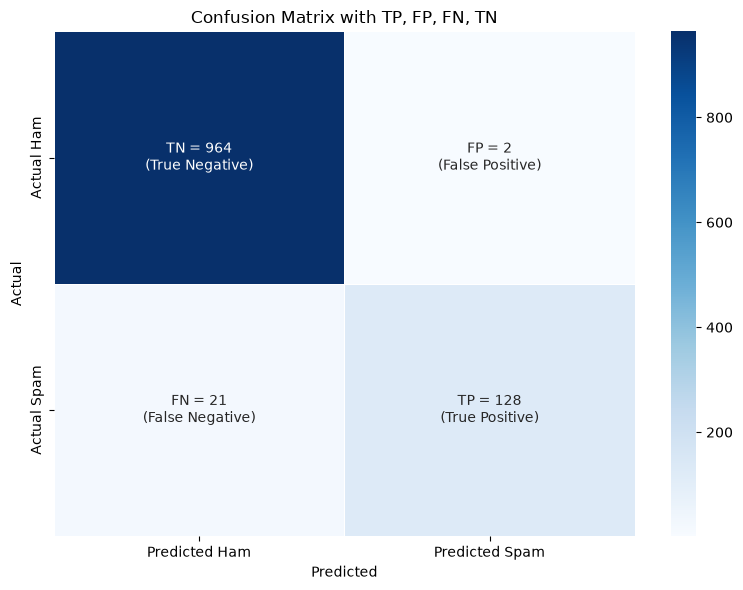

In [13]:

# Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Hitung confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Definisi elemen confusion matrix
TN, FP, FN, TP = conf_matrix.ravel()

# Buat DataFrame confusion matrix
df_conf_matrix = pd.DataFrame(
    conf_matrix,
    index=['Actual Ham', 'Actual Spam'],
    columns=['Predicted Ham', 'Predicted Spam']
)

# Label untuk TN, FP, FN, TP
labels = np.array([
    [f"TN = {TN}\n(True Negative)",
     f"FP = {FP}\n(False Positive)"],
    [f"FN = {FN}\n(False Negative)",
     f"TP = {TP}\n(True Positive)"]
])

# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    df_conf_matrix,
    annot=labels,
    fmt='',
    cmap='Blues',
    linewidths=0.5,
    cbar=True
)

# Tambahkan label
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with TP, FP, FN, TN')

plt.tight_layout()
plt.show()

In [14]:
# Contoh teks baru
new_texts = ["Congratulations! You won a free trip to Bali.",
 "Hey, are you coming to the party tonight?"]
# Preprocess teks baru
new_texts_clean = [clean_text(text) for text in new_texts]
# Transformasi dengan TF-IDF
new_texts_tfidf = vectorizer.transform(new_texts_clean)
# Prediksi
predictions = model.predict(new_texts_tfidf)
# Output hasil prediksi
for text, label in zip(new_texts, predictions):
 print(f"\nMessage: {text} \nPredicted: {'Spam' if label == 1 else 'Ham'}")


Message: Congratulations! You won a free trip to Bali. 
Predicted: Spam

Message: Hey, are you coming to the party tonight? 
Predicted: Ham
